# 03 · Retention & Survival Analysis
## Kaplan-Meier Curves and Churn Dynamics by Subscription Plan

> ⚠️ **All data is fully synthetic.** Retention curves are calibrated against the VBB business case source of truth.

**Business question:** How do retention profiles differ across plans, and what does this imply for LTV and the urgency of D7 intervention?

**Key finding from source of truth:**
- **Família:** 64% cancelled by M2 — the fastest-churning plan
- **Premiere:** 50% cancelled by M4
- **Telecine:** 50% cancelled by M5 — most retained

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import KaplanMeierFitter, NelsonAalenFitter

from src.models.retention_model import RetentionModel
from src.data.synthetic_generator import generate_subscribers

plt.style.use('seaborn-v0_8-whitegrid')
print('Lifelines loaded.')

Lifelines loaded.


In [2]:
rm = RetentionModel()
retention_df = rm.to_dataframe()

print('Expected lifetimes (months):')
for plan in rm.PLANS:
    print(f'  {plan}: {rm.compute_expected_lifetime(plan):.1f} months')

Expected lifetimes (months):
  Familia: 2.3 months
  Premiere: 4.6 months
  Telecine: 5.4 months


## 1. Survival Curves by Plan

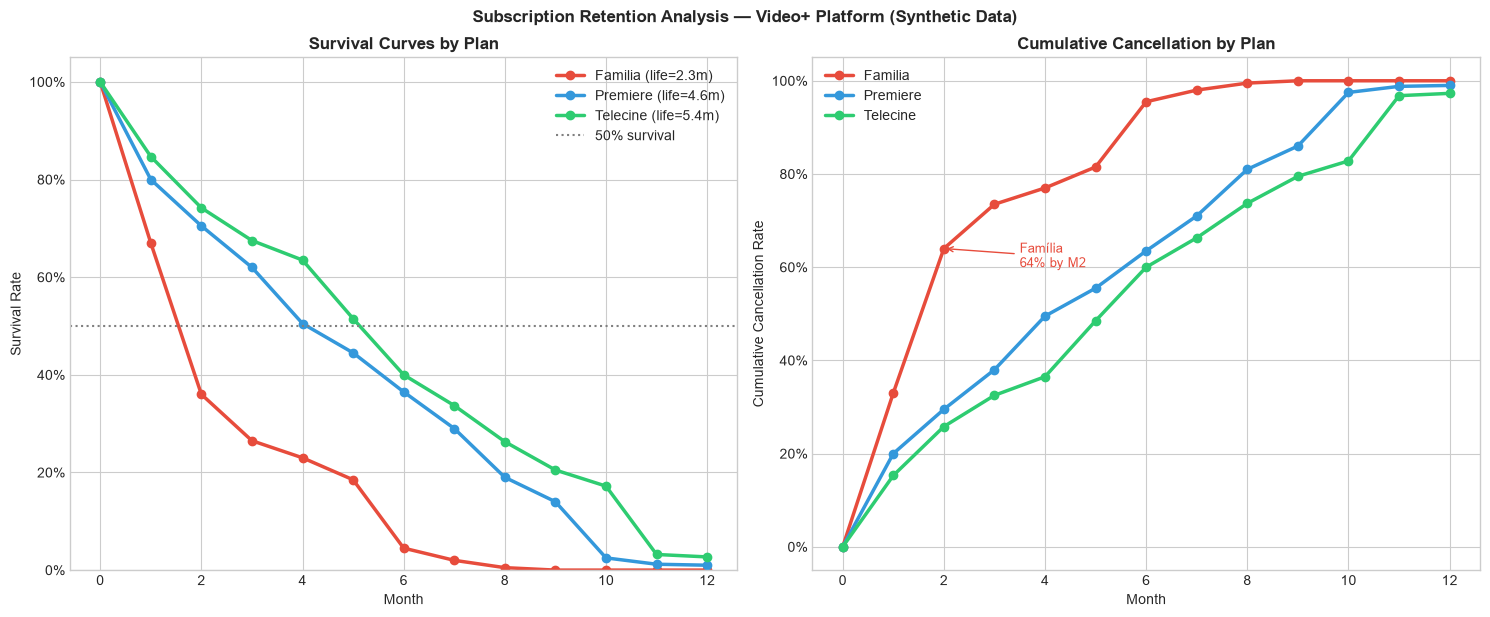

In [3]:
plan_colors = {'Familia': '#e74c3c', 'Premiere': '#3498db', 'Telecine': '#2ecc71'}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Survival curves
for plan in rm.PLANS:
    curve = rm.get_survival_curve(plan)
    months = sorted(curve.keys())
    survival = [curve[m] for m in months]
    life = rm.compute_expected_lifetime(plan)
    axes[0].plot(months, survival, marker='o', linewidth=2.5,
                label=f'{plan} (life={life}m)', color=plan_colors[plan])

axes[0].axhline(0.5, color='gray', linestyle=':', linewidth=1.5, label='50% survival')
axes[0].set_title('Survival Curves by Plan', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Survival Rate')
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

# Cumulative cancellation
for plan in rm.PLANS:
    curve = rm.get_survival_curve(plan)
    months = sorted(curve.keys())
    churn = [1 - curve[m] for m in months]
    axes[1].plot(months, churn, marker='o', linewidth=2.5,
                label=plan, color=plan_colors[plan])

# Annotate key milestones
axes[1].annotate('Família\n64% by M2', xy=(2, 0.64), xytext=(3.5, 0.60),
                arrowprops=dict(arrowstyle='->', color='#e74c3c'), color='#e74c3c', fontsize=9)
axes[1].set_title('Cumulative Cancellation by Plan', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Cumulative Cancellation Rate')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
axes[1].legend()

plt.tight_layout()
plt.suptitle('Subscription Retention Analysis — Video+ Platform (Synthetic Data)', y=1.02, fontweight='bold')
plt.show()

## 2. Hazard Rate Analysis

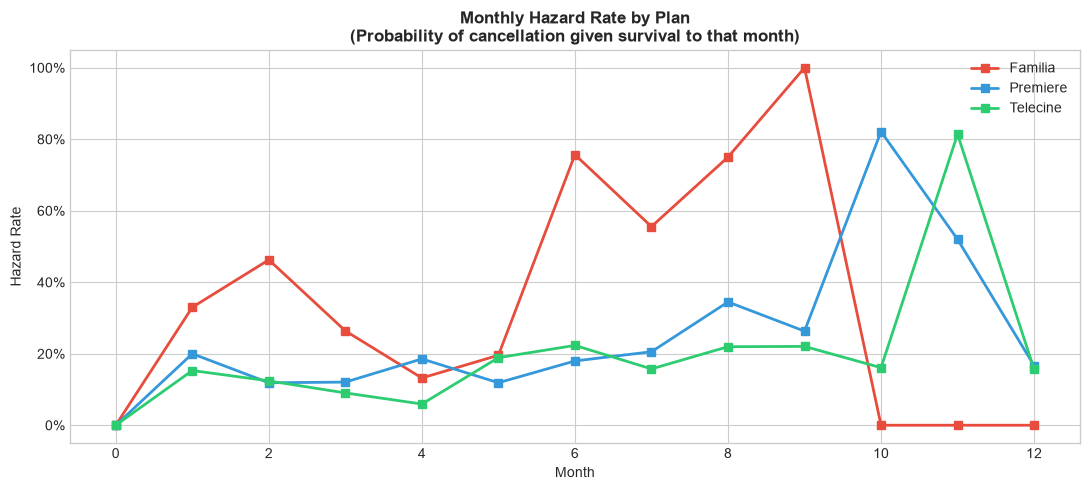


Key insight: Família has a 33% hazard at M1 — the highest early churn rate.
D7 activation targeting Critical subscribers is most valuable for Família plan.


In [4]:
fig, ax = plt.subplots(figsize=(11, 5))

for plan in rm.PLANS:
    plan_data = retention_df[retention_df['plan'] == plan].sort_values('month')
    ax.plot(plan_data['month'], plan_data['hazard'], marker='s', linewidth=2,
            label=plan, color=plan_colors[plan])

ax.set_title('Monthly Hazard Rate by Plan\n(Probability of cancellation given survival to that month)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Hazard Rate')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.legend()
plt.tight_layout()
plt.show()

print('\nKey insight: Família has a 33% hazard at M1 — the highest early churn rate.')
print('D7 activation targeting Critical subscribers is most valuable for Família plan.')

## 3. Kaplan-Meier Fit on Synthetic Subscriber Data

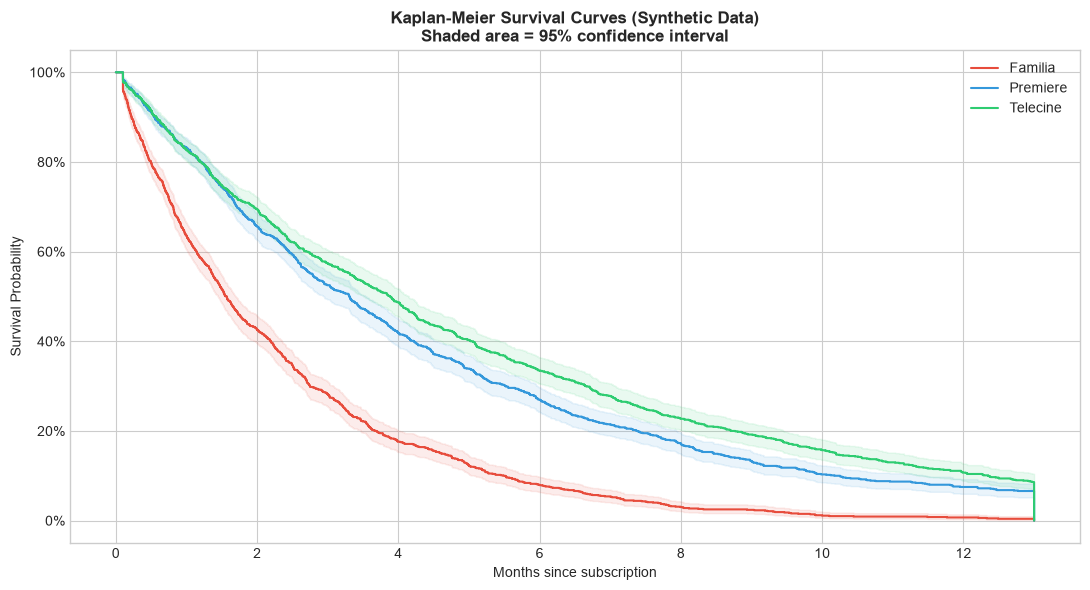

In [5]:
# Generate synthetic event-time data consistent with retention curves
rng = np.random.default_rng(42)
life_params = {'Familia': 2.3, 'Premiere': 4.6, 'Telecine': 5.4}
n_per_plan = 1000

km_records = []
for plan, mu in life_params.items():
    durations = rng.exponential(scale=mu, size=n_per_plan).clip(0.1, 13)
    for d in durations:
        km_records.append({'plan': plan, 'duration': d, 'observed': 1})

km_df = pd.DataFrame(km_records)

fig, ax = plt.subplots(figsize=(11, 6))
for plan in rm.PLANS:
    subset = km_df[km_df['plan'] == plan]
    kmf = KaplanMeierFitter(label=plan)
    kmf.fit(subset['duration'], event_observed=subset['observed'])
    kmf.plot_survival_function(ax=ax, color=plan_colors[plan], ci_show=True, ci_alpha=0.1)

ax.set_title('Kaplan-Meier Survival Curves (Synthetic Data)\nShaded area = 95% confidence interval',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Months since subscription')
ax.set_ylabel('Survival Probability')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout()
plt.show()

## 4. Key Insight

**The retention gap between plans is the core driver of LTV differences.**

| Plan | 50% survival | Expected life | Implication |
|------|-------------|--------------|-------------|
| Família | M1.6 | 2.3 months | Highest churn urgency — D7 activation critical |
| Premiere | M4.0 | 4.6 months | Moderate churn — focus on onboarding quality |
| Telecine | M5.1 | 5.4 months | Best retention — acquisition efficiency opportunity |

D7 behavioral signals predict which subscribers will follow the **Critical path** (early dropout). The VBB framework shifts media spend away from acquiring these subscribers at the top of funnel, while the D7 Activation layer intervenes for those who arrive as Critical despite the mix shift.